In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

In [2]:
df = pd.read_csv("pharmacy_customer_survival_data.csv")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())
print("\nMissing values by column:\n", df.isna().sum())
print("\nChurn event counts (1=churn, 0=censored):\n", df["churn_event"].value_counts())


Dataset shape: (1000, 12)

First 5 rows:
   customer_id   cohort  age  gender   region membership_tier  \
0     PH00001  2024-Q4   73    Male  Central           Basic   
1     PH00002  2024-Q3   21    Male     East          Silver   
2     PH00003  2025-Q1   43  Female  Central            Gold   
3     PH00004  2024-Q4   46  Female     East          Silver   
4     PH00005  2024-Q1   68    Male    South           Basic   

  chronic_care_customer  avg_monthly_spend  orders_first_90_days  \
0                    No             560.06                     2   
1                    No            1411.18                     3   
2                    No            1006.85                     2   
3                   Yes             961.52                     0   
4                    No            2792.17                     1   

  refill_reminder_opt_in  tenure_days  churn_event  
0                    Yes           34            1  
1                    Yes          189            0  
2    

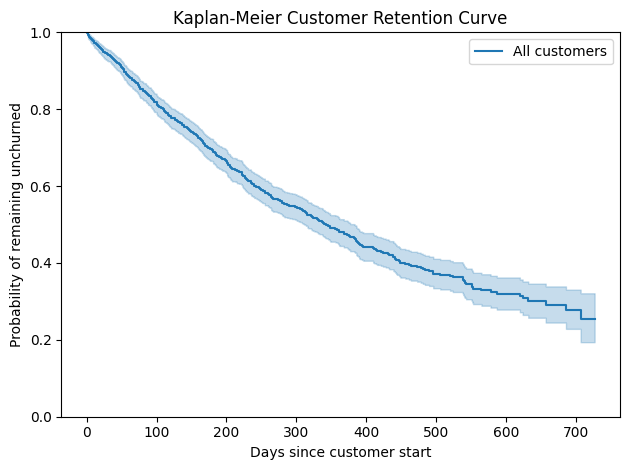

In [3]:
#Kaplan-Meier survival curve for all customers
kmf = KaplanMeierFitter()
kmf.fit(durations=df["tenure_days"], event_observed=df["churn_event"],
        label="All customers")
ax = kmf.plot_survival_function()
ax.set_title("Kaplan-Meier Customer Retention Curve")
ax.set_xlabel("Days since customer start")
ax.set_ylabel("Probability of remaining unchurned")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()


In [4]:
print("\nEstimated retention probabilities:")
for day in [90, 180, 365, 540]:
    estimate = float(kmf.predict(day))
    print(f"Day {day}: {estimate:.3f} ({estimate:.1%})")



Estimated retention probabilities:
Day 90: 0.835 (83.5%)
Day 180: 0.694 (69.4%)
Day 365: 0.480 (48.0%)
Day 540: 0.353 (35.3%)


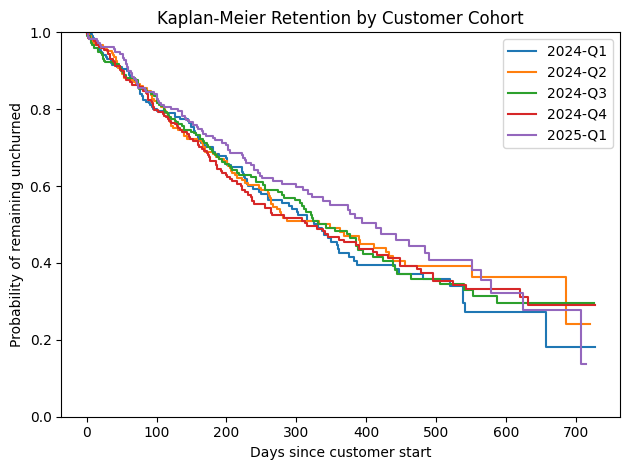

In [5]:
#Kaplan-Meier curves by customer cohort
plt.figure()
for cohort, group in df.groupby("cohort"):
    km = KaplanMeierFitter()
    km.fit(group["tenure_days"], event_observed=group["churn_event"], label=cohort)
    km.plot_survival_function(ci_show=False)
plt.title("Kaplan-Meier Retention by Customer Cohort")
plt.xlabel("Days since customer start")
plt.ylabel("Probability of remaining unchurned")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [6]:
#Log-rank test comparing two cohorts (example: earliest two cohorts)
cohort_names = sorted(df["cohort"].unique())
if len(cohort_names) >= 2:
    a = df[df["cohort"] == cohort_names[0]]
    b = df[df["cohort"] == cohort_names[1]]
    result = logrank_test(
        a["tenure_days"], b["tenure_days"],
        event_observed_A=a["churn_event"],
        event_observed_B=b["churn_event"]
    )
    print(f"\nLog-rank test: {cohort_names[0]} vs {cohort_names[1]}")
    print(f"Test statistic: {result.test_statistic:.3f}")
    print(f"P-value: {result.p_value:.5f}")
    print("Interpretation: a p-value below 0.05 suggests evidence of different survival "
          "curves for these two cohorts; it does not prove causation.")



Log-rank test: 2024-Q1 vs 2024-Q2
Test statistic: 0.235
P-value: 0.62758
Interpretation: a p-value below 0.05 suggests evidence of different survival curves for these two cohorts; it does not prove causation.



Cox proportional hazards model summary:
                                coef  exp(coef)  se(coef)         p  \
covariate                                                             
age                        -0.000463   0.999537  0.002462  0.850897   
avg_monthly_spend           0.000016   1.000016  0.000058  0.780383   
orders_first_90_days       -0.049132   0.952056  0.023878  0.039626   
membership_tier_Gold       -0.465855   0.627598  0.142359  0.001066   
membership_tier_Silver     -0.119280   0.887559  0.097996  0.223528   
chronic_care_customer_Yes  -0.441624   0.642991  0.101964  0.000015   
refill_reminder_opt_in_Yes -0.414018   0.660989  0.088436  0.000003   
gender_Male                -0.101626   0.903367  0.089325  0.255240   
gender_Other                0.312800   1.367248  0.285496  0.273237   
region_East                 0.053010   1.054440  0.138092  0.701070   
region_North                0.049267   1.050500  0.142291  0.729163   
region_South                0.012564

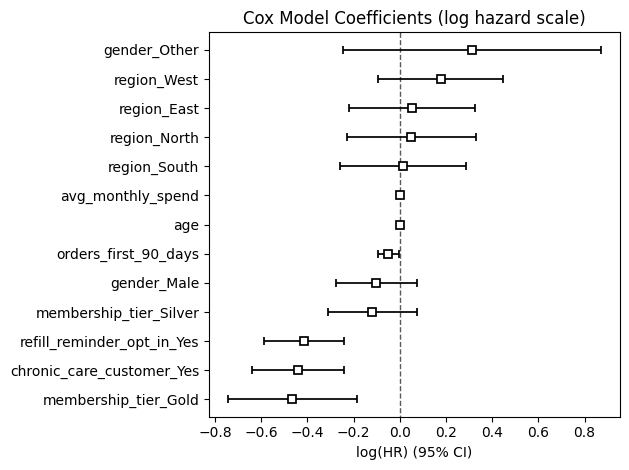

In [7]:
#Cox proportional hazards model
# Encode categorical variables with one-hot encoding. Use one category as the reference.
model_columns = [
    "tenure_days", "churn_event", "age", "avg_monthly_spend",
    "orders_first_90_days", "membership_tier", "chronic_care_customer",
    "refill_reminder_opt_in", "gender", "region"
]
model_df = df[model_columns].copy()
model_df = pd.get_dummies(
    model_df,
    columns=["membership_tier", "chronic_care_customer",
             "refill_reminder_opt_in", "gender", "region"],
    drop_first=True,
    dtype=int
)

cph = CoxPHFitter()
cph.fit(model_df, duration_col="tenure_days", event_col="churn_event")
print("\nCox proportional hazards model summary:")
print(cph.summary[["coef", "exp(coef)", "se(coef)", "p", "exp(coef) lower 95%", "exp(coef) upper 95%"]])
plt.figure()
cph.plot()
plt.title("Cox Model Coefficients (log hazard scale)")
plt.tight_layout()
plt.show()




In [8]:
#Simple cohort summary export
cohort_summary = df.groupby("cohort").agg(
    customers=("customer_id", "count"),
    churn_events=("churn_event", "sum"),
    median_observed_tenure_days=("tenure_days", "median"),
    average_monthly_spend=("avg_monthly_spend", "mean")
).reset_index()
cohort_summary["observed_churn_rate"] = cohort_summary["churn_events"] / cohort_summary["customers"]
print("\nCohort summary:\n", cohort_summary.to_string(index=False))




Cohort summary:
  cohort  customers  churn_events  median_observed_tenure_days  average_monthly_spend  observed_churn_rate
2024-Q1        200           108                        223.5            1382.148500             0.540000
2024-Q2        185            97                        233.0            1392.122324             0.524324
2024-Q3        218           113                        217.0            1389.150872             0.518349
2024-Q4        217           121                        208.0            1359.184793             0.557604
2025-Q1        180            88                        251.5            1430.782556             0.488889
